<a href="https://colab.research.google.com/github/Lu-Melo/Actividad-Tabu-Search-Horas-de-Espera-CsTec/blob/main/Actividad_notebook_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Un día en pabellón

### Mini proyecto — Curso Ciencia y Tecnología

---

Un hospital tiene que operar a un grupo de pacientes en un día. Cada paciente pasa
por tres lugares distintos, siempre en el mismo orden:

> **Anestesia** → **Cirugía** → **Recuperación**

Primero lo preparan y lo anestesian, después lo operan, y por último lo vigilan
mientras despierta. *(En la literatura de investigación estas tres etapas se conocen
por sus siglas APR, OR y ARR; acá usaremos los nombres completos.)*

Hay **3 salas para cada etapa**, y son intercambiables entre sí: para un paciente da
lo mismo entrar al pabellón 1, al 2 o al 3.

Entre un paciente y el siguiente hay que **acondicionar la sala** (30 minutos) y, al
terminar, **asearla** (20 minutos). Ojo con esto: acondicionar la sala es trabajo
sobre la *sala*, no sobre el paciente. No confundirlo con la etapa de anestesia.

Y hay una regla que lo complica todo:

> ### Un paciente no puede salir de una sala hasta que la siguiente lo reciba.

Si recuperación está llena, el paciente se queda en el pabellón esperando. Y ese
pabellón queda ocupado, aunque la cirugía haya terminado hace rato. No se puede dejar
a un paciente recién operado en un pasillo: alguien tiene que estar vigilándolo.

Esto tiene un nombre en la literatura: **política de bloqueo sin buffer**. Y su
consecuencia es poco intuitiva: **el atasco se propaga hacia atrás**. La sala de
recuperación se llena, eso tapa los pabellones, y los pabellones tapados terminan
frenando la anestesia. Un pabellón bloqueado es un pabellón que no opera a nadie,
y en un hospital real eso cuesta del orden de 35 dólares por minuto.

**La pregunta del proyecto es fácil de enunciar:**

> ## ¿En qué orden conviene atender a los pacientes para cerrar lo antes posible?

Cambiar el orden no cuesta un peso. No hay que construir nada ni contratar a nadie.
Y como vas a ver en un minuto, cambia el resultado en horas.

El instante en que el último paciente termina se llama **makespan**, y es lo único
que hay que minimizar. Es, literalmente, a qué hora se puede cerrar el recinto.

---

### Cómo funciona este proyecto

**Lo que tú tienes que hacer:** escribir un programa que encuentre buenos órdenes.
Todo lo demás ya está resuelto acá: simular el día, respetar las reglas, calcular los
tiempos, dibujar los gráficos.

**Lo que se entrega:** tus mejores órdenes para 30 días distintos, más un informe con
tres experimentos.

Las secciones 1 a 5 son para entender el problema y las herramientas. **Tu trabajo
empieza en la sección 6**, y ahí encontrarás una lista de pasos concreta.

## Antes de empezar

Ejecuta la celda de abajo. Escribe sola todo lo necesario: el simulador del día
quirúrgico y los datos de los 30 días. No hay que subir ningún archivo ni instalar
nada.

El código está oculto para no distraer, pero no es secreto: **haz doble clic sobre la
celda si quieres verlo**. También queda escrito en el archivo `mini_or.py`, que puedes
abrir desde el panel de archivos de Colab, a la izquierda. Vale la pena mirarlo cuando
llegues a la sección 6.

Si Colab reinicia el entorno, vuelve a ejecutarla.

In [ ]:
#@title Preparacion del entorno &mdash; ejecuta esta celda y sigue { display-mode: "form" }
# Escribe el simulador y los datos de los 30 dias. Nada que modificar aqui.

codigo_simulador = r'''"""
mini_or.py -- Simulador del dia quirurgico y herramientas del mini proyecto.

Un dia quirurgico con tres etapas en serie:

    Anestesia -> Cirugia -> Recuperacion

(en la literatura estas tres etapas se conocen como APR, OR y ARR)

Cada etapa tiene varias salas identicas en paralelo. Antes de recibir a cada
paciente hay que acondicionar la sala durante t_set minutos, y despues de que
se retira hay que asearla durante t_cln minutos. Ojo: eso es preparacion de la
SALA, distinta de la etapa clinica de anestesia.

REGLA DE BLOQUEO (sin buffer): un paciente no puede abandonar una sala hasta
que la siguiente lo reciba. La sala anterior queda ocupada mientras tanto,
aunque medicamente ya este libre.

Una solucion es UN ORDEN de los pacientes. El simulador lo convierte en un
calendario que cumple todas las reglas.

Vocabulario de los argumentos que se repiten:

    dia   : arreglo (n, 3) con los tiempos de atencion medica de cada paciente
            en cada etapa, en minutos. Se obtiene con cargar("I01").
    orden : lista con los indices de los pacientes, en el orden en que entran.
"""

import numpy as np

# ----------------------------------------------------------------------------
# Parametros del modelo, fijos para todo el mini proyecto
# ----------------------------------------------------------------------------
T_SET = 30      # acondicionamiento de la sala antes de cada paciente, minutos
T_CLN = 20      # aseo de la sala, minutos
W_MAX = 25      # espera clinicamente aceptable entre etapas, minutos
R = (3, 3, 3)   # salas en paralelo en anestesia, cirugia y recuperacion

NOMBRES_ETAPA = ("Anestesia", "Cirugía", "Recuperación")


# ----------------------------------------------------------------------------
# El simulador
# ----------------------------------------------------------------------------
def simular_dia(orden, dia, t_set=T_SET, t_cln=T_CLN, r=R):
    """Convierte un orden de pacientes en un calendario que cumple las reglas.

    Devuelve un diccionario con:
        makespan : instante en que se termina de asear la ultima sala de
                   recuperacion, es decir, a que hora cierra el recinto
        inicio   : arreglo (n, 3) con el instante en que empieza la atencion
        sala     : arreglo (n, 3) con la sala asignada en cada etapa
        espera   : arreglo (n, 2) con la espera anestesia->cirugia y
                   cirugia->recuperacion
    """
    dia = np.asarray(dia, dtype=float)
    n = dia.shape[0]

    libre = [np.zeros(r[i]) for i in range(3)]   # cuando se libera cada sala
    inicio = np.zeros((n, 3))
    sala = np.zeros((n, 3), dtype=int)

    for j in orden:
        listo = 0.0          # instante en que el paciente queda disponible
        s_ant = None
        for i in range(3):
            m = int(np.argmin(libre[i]))
            # la preparacion de la sala puede adelantarse a la llegada del paciente
            s = max(libre[i][m] + t_set, listo)

            if i > 0:
                # el paciente recien deja la etapa anterior cuando entra a esta
                libre[i - 1][s_ant] = s + t_cln

            inicio[j, i] = s
            sala[j, i] = m
            libre[i][m] = np.inf     # se fija al conocer el inicio en la etapa siguiente
            listo = s + dia[j, i]
            s_ant = m

        libre[2][s_ant] = inicio[j, 2] + dia[j, 2] + t_cln

    espera = np.column_stack([
        inicio[:, 1] - (inicio[:, 0] + dia[:, 0]),
        inicio[:, 2] - (inicio[:, 1] + dia[:, 1]),
    ])
    makespan = float(np.max(inicio[:, 2] + dia[:, 2] + t_cln))

    return {"makespan": makespan, "inicio": inicio, "sala": sala, "espera": espera}


# ----------------------------------------------------------------------------
# Verificador
# ----------------------------------------------------------------------------
def verificar(orden, dia, cal, t_set=T_SET, t_cln=T_CLN, r=R, tol=1e-6):
    """Revisa que un calendario respete todas las reglas.

    Devuelve una lista de errores. Lista vacia significa que esta todo bien.
    """
    dia = np.asarray(dia, dtype=float)
    n = dia.shape[0]
    errores = []

    if sorted(orden) != list(range(n)):
        errores.append("el orden no contiene exactamente una vez a cada paciente")
        return errores

    ini, sal = cal["inicio"], cal["sala"]

    # las etapas van en orden
    for j in range(n):
        for i in range(2):
            if ini[j, i + 1] < ini[j, i] + dia[j, i] - tol:
                errores.append(
                    f"paciente {j}: entra a {NOMBRES_ETAPA[i+1]} antes de terminar "
                    f"{NOMBRES_ETAPA[i]}")

    # una sala atiende a un paciente a la vez, contando preparacion y aseo
    for i in range(3):
        for m in range(r[i]):
            ocupa = []
            for j in range(n):
                if sal[j, i] == m:
                    fin = (ini[j, i + 1] if i < 2 else ini[j, i] + dia[j, i]) + t_cln
                    ocupa.append((ini[j, i] - t_set, fin, j))
            ocupa.sort()
            for a, b in zip(ocupa, ocupa[1:]):
                if b[0] < a[1] - tol:
                    errores.append(
                        f"{NOMBRES_ETAPA[i]} sala {m}: se solapan los pacientes "
                        f"{a[2]} y {b[2]}")

    if np.any(cal["espera"] < -tol):
        errores.append("hay esperas negativas: alguien sale antes de ser recibido")

    return errores


# ----------------------------------------------------------------------------
# Cota inferior
# ----------------------------------------------------------------------------
def cota_inferior(dia, t_set=T_SET, t_cln=T_CLN, r=R):
    """Minimo teorico del makespan. Ninguna solucion valida puede quedar debajo.

    Es el mayor de dos razonamientos:
      (a) ningun paciente puede terminar antes de recorrer sus tres etapas;
      (b) las salas de una etapa no pueden procesar toda su carga mas rapido
          que repartiendosela perfectamente.
    """
    dia = np.asarray(dia, dtype=float)
    ruta = float(np.max(t_set + dia.sum(axis=1) + t_cln))
    carga = max((dia[:, i] + t_set + t_cln).sum() / r[i] for i in range(3))
    return max(ruta, carga)


# ----------------------------------------------------------------------------
# Reglas de despacho
# ----------------------------------------------------------------------------
def regla(nombre, dia):
    """Devuelve el orden que produce una regla de despacho clasica.

    FIFO : orden de llegada
    SPT  : Shortest Processing Time, los pacientes mas cortos primero
    LPT  : Longest Processing Time, los mas largos primero
    """
    dia = np.asarray(dia, dtype=float)
    total = dia.sum(axis=1)
    if nombre == "FIFO":
        return list(range(len(total)))
    if nombre == "SPT":
        return list(np.argsort(total, kind="stable"))
    if nombre == "LPT":
        return list(np.argsort(-total, kind="stable"))
    raise ValueError(f"regla desconocida: {nombre}")


REGLAS = ("FIFO", "SPT", "LPT")


def mejor_regla(dia):
    """Makespan de la mejor de las tres reglas para este dia."""
    return min(simular_dia(regla(nm, dia), dia)["makespan"] for nm in REGLAS)


# ----------------------------------------------------------------------------
# Limite de intentos
# ----------------------------------------------------------------------------
class SinIntentos(Exception):
    """Se levanta cuando una busqueda gasta todos sus intentos."""


class Evaluador:
    """Envuelve al simulador y cuenta cuantas veces se le llama.

    Cada llamada es un intento: probar un orden y ver que makespan da. El
    proyecto permite un maximo por dia; pasarse levanta SinIntentos.

    Atributos utiles despues de una busqueda:
        mejor      : el mejor makespan visto
        mejor_orden: el orden que lo produjo
        usados     : cuantos intentos se gastaron
        historial  : lista de (intentos, makespan) cada vez que hubo una mejora
    """

    def __init__(self, dia, intentos=20_000):
        self.dia = np.asarray(dia, dtype=float)
        self.intentos = intentos
        self.usados = 0
        self.mejor = np.inf
        self.mejor_orden = None
        self.historial = []

    def __call__(self, orden):
        if self.usados >= self.intentos:
            raise SinIntentos(f"se agotaron los {self.intentos} intentos permitidos")
        self.usados += 1
        mk = simular_dia(orden, self.dia)["makespan"]
        if mk < self.mejor:
            self.mejor = mk
            self.mejor_orden = list(orden)
            self.historial.append((self.usados, mk))
        return mk


# ----------------------------------------------------------------------------
# Generador de dias (uso interno, para construir el conjunto de instancias)
# ----------------------------------------------------------------------------
def generar_dia(n, rng):
    """Genera los tiempos de atencion de n pacientes.

    Mezcla casos cortos, medianos y largos, para que el orden importe.
    """
    tipo = rng.choice(3, size=n, p=[0.45, 0.35, 0.20])
    escala_or = np.array([55.0, 100.0, 165.0])[tipo]
    d = np.column_stack([
        rng.normal(28, 7, n),                       # anestesia
        rng.normal(escala_or, escala_or * 0.18),    # cirugia
        rng.normal(escala_or * 0.75 + 25, 18, n),   # recuperacion
    ])
    return np.clip(np.round(d), 10, None)


# ============================================================================
# VISUALIZACION
# ============================================================================
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

_GRIS = "#c9ccd1"
_ROJO = "#e05252"
_COLORES = plt.get_cmap("tab20").colors


def _hm(x, _=None):
    h, m = divmod(int(round(x)), 60)
    return f"{h}:{m:02d}"


def dibujar_gantt(orden, dia, titulo=None, figsize=(13, 5.4)):
    """Dibuja el calendario: una fila por sala, agrupadas por etapa.

    Los bloques rayados en rojo son pacientes que ya terminaron su atencion
    pero no pueden salir porque la etapa siguiente esta llena. Esa sala esta
    ocupada sin atender a nadie: es el efecto de la regla de bloqueo.
    """
    dia = np.asarray(dia, float)
    cal = simular_dia(orden, dia)
    ini, sal = cal["inicio"], cal["sala"]
    n = len(dia)

    filas, etiquetas = [], []
    for i in range(3):
        for m in range(R[i]):
            filas.append((i, m))
            etiquetas.append(f"{NOMBRES_ETAPA[i]} {m + 1}")
    ypos = {rm: k for k, rm in enumerate(filas)}

    fig, ax = plt.subplots(figsize=figsize)
    bloqueado = 0.0
    ancho_total = float(np.max(ini[:, 2] + dia[:, 2])) + T_CLN
    for j in range(n):
        col = _COLORES[j % len(_COLORES)]
        # texto oscuro sobre colores claros, claro sobre colores oscuros
        lum = 0.299 * col[0] + 0.587 * col[1] + 0.114 * col[2]
        tinta = "#111111" if lum > 0.6 else "white"
        for i in range(3):
            y = ypos[(i, int(sal[j, i]))]
            s = ini[j, i]
            fin_med = s + dia[j, i]
            salida = ini[j, i + 1] if i < 2 else fin_med

            ax.barh(y, T_SET, left=s - T_SET, height=.62, color=col, alpha=.30)
            ax.barh(y, dia[j, i], left=s, height=.62, color=col,
                    edgecolor="white", linewidth=.6)
            if salida > fin_med + 1e-6:
                bloqueado += salida - fin_med
                ax.barh(y, salida - fin_med, left=fin_med, height=.62, color=_ROJO,
                        alpha=.55, hatch="///", edgecolor=_ROJO, linewidth=0)
            ax.barh(y, T_CLN, left=salida, height=.62, color=_GRIS, alpha=.85)

            # etiqueta A/C/R + numero de paciente, si el bloque da el ancho
            texto = f"{'ACR'[i]}{j}"
            frac = dia[j, i] / ancho_total
            fs = (7.5 if frac >= 0.0105 * len(texto)
                  else 6.0 if frac >= 0.0082 * len(texto) else None)
            if fs:
                ax.text(s + dia[j, i] / 2, y, texto, ha="center", va="center",
                        fontsize=fs, color=tinta, weight="bold")

    for k in (R[0] - .5, R[0] + R[1] - .5):
        ax.axhline(k, color="0.35", lw=1.1)

    mk = cal["makespan"]
    ax.set_yticks(range(len(filas)))
    ax.set_yticklabels(etiquetas, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("tiempo desde el inicio de la jornada (h:mm)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(_hm))
    ax.set_xlim(-T_SET - 10, mk * 1.13)
    ax.axvline(mk, color="black", ls="--", lw=1.2)
    ax.text(mk + mk * .008, -.15, f"cierre\n{_hm(mk)}", fontsize=9, va="top")
    ax.set_title(titulo or "Calendario del dia", fontsize=12, loc="left", pad=26)
    ax.text(0, 1.015, f"makespan {mk:.0f} min   |   {bloqueado:.0f} min de sala "
            f"ocupada sin atender a nadie",
            transform=ax.transAxes, fontsize=9.5, color="0.35")
    ax.legend(handles=[
        Patch(color="#4878a8", alpha=.30, label=f"acondicionar la sala ({T_SET} min)"),
        Patch(color="#4878a8", label="atencion al paciente"),
        Patch(facecolor=_ROJO, alpha=.55, hatch="///", label="bloqueado: no puede salir"),
        Patch(color=_GRIS, label=f"aseo ({T_CLN} min)")],
        loc="upper center", bbox_to_anchor=(.5, -.16), ncol=4, frameon=False, fontsize=9)
    ax.grid(axis="x", alpha=.25)
    fig.tight_layout()
    return fig


def ficha_dia(dia, nombre=""):
    """Muestra de que esta hecho un dia quirurgico, sin tablas de numeros."""
    dia = np.asarray(dia, float)
    n = len(dia)
    orden = np.argsort(-dia.sum(axis=1))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6),
                                 gridspec_kw={"width_ratios": [2, 1]})
    izq = np.zeros(n)
    for i, (col, et) in enumerate(zip(["#6a9fd8", "#e0a03c", "#7bb87b"],
                                      NOMBRES_ETAPA)):
        a1.barh(range(n), dia[orden, i], left=izq, color=col, label=et, height=.72)
        izq += dia[orden, i]
    a1.set_yticks(range(n))
    a1.set_yticklabels([f"paciente {j}" for j in orden], fontsize=8)
    a1.invert_yaxis()
    a1.set_xlabel("minutos de atencion al paciente")
    a1.legend(ncol=3, frameon=False, fontsize=9, loc="lower right")
    a1.set_title(f"{nombre}: {n} pacientes, del mas largo al mas corto", fontsize=10)
    a1.grid(axis="x", alpha=.25)

    tot = dia.sum(axis=1)
    a2.hist(tot, bins=8, color="#8899aa", edgecolor="white")
    a2.set_xlabel("duracion total por paciente (min)")
    a2.set_ylabel("pacientes")
    a2.set_title(f"del mas corto ({tot.min():.0f} min) al mas largo ({tot.max():.0f} min)",
                 fontsize=10)
    a2.grid(axis="y", alpha=.25)
    fig.tight_layout()
    return fig


def termometro(valores, dia, nombre=""):
    """valores: dict {etiqueta: makespan}. Ubica cada resultado en el corredor."""
    dia = np.asarray(dia, float)
    lb = cota_inferior(dia)
    peor = max(list(valores.values()) +
               [simular_dia(regla(nm, dia), dia)["makespan"] for nm in REGLAS])
    fig, ax = plt.subplots(figsize=(11, 1.15 + .45 * len(valores)))
    ax.axvspan(lb, peor, color="#f2f4f6")
    ax.axvline(lb, color="#2e7d32", lw=2.2)
    for k, (et, v) in enumerate(valores.items()):
        frac = (v - lb) / max(peor - lb, 1e-9)
        col = "#2e7d32" if frac < .25 else "#e0a03c" if frac < .7 else "#c0392b"
        ax.barh(k, v - lb, left=lb, height=.5, color=col, alpha=.9)
        ax.text(v + (peor - lb) * .02, k,
                f"{v:.0f} min   (+{100 * (v / lb - 1):.0f}% sobre el minimo)",
                va="center", fontsize=9.5)
    ax.set_yticks(range(len(valores)))
    ax.set_yticklabels(list(valores), fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(lb - (peor - lb) * .1, lb + (peor - lb) * 1.75)
    ax.set_xlabel("makespan (min)")
    ax.set_title(f"{nombre}   |   minimo teorico = {lb:.0f} min (linea verde: nadie "
                 f"puede quedar a la izquierda)", fontsize=10.5, loc="left")
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", alpha=.2)
    fig.tight_layout()
    return fig


def panel_resultados(tabla, columnas=("mejor_regla", "metodo_ejemplo", "mi_metodo")):
    """Vista de los 30 dias: cuanto margen queda sobre el minimo teorico."""
    t = tabla.sort_values(["n", "instancia"])
    x = np.arange(len(t))
    presentes = [c for c in columnas if c in t]
    anchos = np.linspace(.8, .3, len(presentes))
    colores = ["#c0392b", "#e0a03c", "#2e7d32"]
    fig, ax = plt.subplots(figsize=(12, 4))
    for c, w, col in zip(presentes, anchos, colores):
        ax.bar(x, 100 * (t[c] / t["cota_inferior"] - 1), width=w, color=col,
               alpha=.85, label=c.replace("_", " "))
    ax.axhline(0, color="#2e7d32", lw=2)
    ax.set_xticks(x)
    ax.set_xticklabels(t["instancia"], rotation=90, fontsize=7.5)
    ax.set_ylabel("% sobre el minimo teorico")
    ax.set_title("Margen que queda en cada dia (mas bajo es mejor)",
                 fontsize=11, loc="left")
    ax.legend(frameon=False, ncol=len(presentes))
    ax.grid(axis="y", alpha=.25)
    fig.tight_layout()
    return fig


def grafico_convergencia(ev, dia, titulo=""):
    """Como fue mejorando una busqueda a medida que gasto intentos."""
    h = np.array(ev.historial)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.step(h[:, 0], h[:, 1], where="post", lw=2)
    ax.axhline(cota_inferior(dia), ls="--", color="#2e7d32", label="minimo teorico")
    ax.set_xlabel("intentos usados")
    ax.set_ylabel("mejor makespan encontrado")
    ax.set_title(titulo or "Como fue mejorando la busqueda", loc="left")
    ax.legend(frameon=False)
    ax.grid(alpha=.25)
    fig.tight_layout()
    return fig


def grafico_intentos(barrido):
    """Resultado de barrer_intentos: ratio medio segun cuantos intentos se dan."""
    fig, ax = plt.subplots(figsize=(9, 3.6))
    for etiqueta, g in barrido.groupby("metodo"):
        r = g.groupby("intentos")["ratio"].agg(["mean", "std"])
        ax.errorbar(r.index, r["mean"], yerr=r["std"], marker="o", capsize=4,
                    lw=2, label=etiqueta)
    ax.set_xscale("log")
    ax.set_xlabel("intentos permitidos (escala logaritmica)")
    ax.set_ylabel("ratio respecto de la mejor regla")
    ax.set_title("Cuanto rinde cada intento adicional", loc="left")
    ax.legend(frameon=False)
    ax.grid(alpha=.25)
    fig.tight_layout()
    return fig


# ============================================================================
# EXPERIMENTOS
# ============================================================================
import pandas as pd
from scipy.stats import wilcoxon


def _barra(iterable, desc=""):
    try:
        from tqdm.auto import tqdm
        return tqdm(iterable, desc=desc)
    except Exception:
        return iterable


def tabla_resultados(dias, metodos, intentos=20_000, seed=0):
    """Corre uno o mas metodos en todos los dias y arma la tabla de resultados.

    dias    : dict {nombre: arreglo del dia}
    metodos : dict {etiqueta: funcion(dia, intentos, seed) -> Evaluador}

    Devuelve un DataFrame con una fila por dia: el minimo teorico, las tres
    reglas, la mejor de ellas, y una columna por metodo.
    """
    filas = []
    for nombre in _barra(list(dias), "resolviendo"):
        d = dias[nombre]
        f = {"instancia": nombre, "n": len(d),
             "cota_inferior": round(cota_inferior(d), 1)}
        for nm in REGLAS:
            f[nm] = simular_dia(regla(nm, d), d)["makespan"]
        f["mejor_regla"] = min(f[nm] for nm in REGLAS)
        for etiqueta, met in metodos.items():
            f[etiqueta] = met(d, intentos, seed).mejor
        filas.append(f)
    return pd.DataFrame(filas)


def barrer_intentos(metodos, dias, lista_intentos, semillas=3):
    """Repite los metodos con distintos limites de intentos y varias semillas.

    Devuelve un DataFrame largo con una fila por (metodo, dia, intentos, semilla)
    y el ratio respecto de la mejor regla de ese dia.
    """
    filas = []
    for nombre in _barra(list(dias), "barriendo"):
        d = dias[nombre]
        base = mejor_regla(d)
        for etiqueta, met in metodos.items():
            for lim in lista_intentos:
                for s in range(semillas):
                    filas.append({"metodo": etiqueta, "instancia": nombre,
                                  "intentos": lim, "semilla": s,
                                  "ratio": met(d, lim, s).mejor / base})
    return pd.DataFrame(filas)


def _holm(pvalores):
    """Corrige los p-valores cuando se hacen varias comparaciones a la vez."""
    p = np.asarray(pvalores, float)
    m = len(p)
    orden = np.argsort(p)
    ajustado = np.empty(m)
    acumulado = 0.0
    for k, i in enumerate(orden):
        acumulado = max(acumulado, (m - k) * p[i])
        ajustado[i] = min(acumulado, 1.0)
    return ajustado


def comparar_todos(resultados, alfa=0.05):
    """Compara varios metodos entre si, dia por dia.

    resultados: dict {etiqueta: lista de makespan, uno por dia}

    Para cada par calcula la diferencia dia a dia, cuenta victorias y aplica el
    test de Wilcoxon pareado. Al final ajusta los p-valores con Holm, porque al
    hacer varias comparaciones a la vez sube la probabilidad de que alguna salga
    significativa por casualidad.
    """
    etiquetas = list(resultados)
    pares, ps = [], []
    for i in range(len(etiquetas)):
        for j in range(i + 1, len(etiquetas)):
            a, b = etiquetas[i], etiquetas[j]
            x = np.asarray(resultados[a], float)
            y = np.asarray(resultados[b], float)
            pares.append((a, b, x - y))
            ps.append(wilcoxon(x, y).pvalue if np.any(x != y) else 1.0)

    ajustados = _holm(ps)
    for (a, b, d), p, pa in zip(pares, ps, ajustados):
        gana_a = int((d < 0).sum())
        gana_b = int((d > 0).sum())
        empatan = int((d == 0).sum())
        veredicto = "la diferencia es real" if pa < alfa else "no se pueden distinguir"
        print(f"{a}  vs  {b}")
        print(f"    gana {a} en {gana_a} dias   |   gana {b} en {gana_b}"
              + (f"   |   empatan en {empatan}" if empatan else ""))
        print(f"    mediana de la diferencia: {np.median(d):+.1f} min   "
              f"(promedio {d.mean():+.1f})")
        print(f"    Wilcoxon pareado: p = {p:.5f}  ->  p ajustado por Holm = "
              f"{pa:.5f}  ->  {veredicto}")
        print()
    return pd.DataFrame({"comparacion": [f"{a} vs {b}" for a, b, _ in pares],
                         "p": ps, "p_holm": ajustados})
'''

datos_dias = r'''instancia,n,paciente,anestesia,cirugia,recuperacion
I01,8,0,26,51,78
I01,8,1,26,110,133
I01,8,2,33,98,87
I01,8,3,32,41,91
I01,8,4,28,50,44
I01,8,5,27,112,103
I01,8,6,29,158,128
I01,8,7,24,54,91
I02,8,0,29,80,61
I02,8,1,24,259,154
I02,8,2,22,129,123
I02,8,3,38,63,56
I02,8,4,32,145,131
I02,8,5,33,65,48
I02,8,6,43,92,83
I02,8,7,22,55,40
I03,8,0,44,70,51
I03,8,1,24,87,112
I03,8,2,36,56,77
I03,8,3,31,108,65
I03,8,4,27,176,116
I03,8,5,23,128,126
I03,8,6,37,88,102
I03,8,7,27,53,103
I04,8,0,38,56,86
I04,8,1,29,89,92
I04,8,2,28,55,54
I04,8,3,32,130,119
I04,8,4,31,132,162
I04,8,5,36,114,125
I04,8,6,22,64,70
I04,8,7,12,108,129
I05,8,0,34,83,98
I05,8,1,41,128,85
I05,8,2,21,211,164
I05,8,3,11,60,41
I05,8,4,39,99,92
I05,8,5,18,103,59
I05,8,6,29,44,75
I05,8,7,30,53,80
I06,8,0,22,69,80
I06,8,1,38,51,86
I06,8,2,30,101,114
I06,8,3,32,74,63
I06,8,4,23,66,10
I06,8,5,37,111,110
I06,8,6,22,197,151
I06,8,7,16,143,142
I07,8,0,24,114,101
I07,8,1,29,111,88
I07,8,2,31,102,89
I07,8,3,28,50,38
I07,8,4,29,59,46
I07,8,5,30,191,121
I07,8,6,35,133,138
I07,8,7,24,56,56
I08,8,0,39,76,42
I08,8,1,39,80,64
I08,8,2,38,118,106
I08,8,3,43,184,166
I08,8,4,19,132,147
I08,8,5,33,80,95
I08,8,6,33,62,66
I08,8,7,31,54,69
I09,8,0,15,62,48
I09,8,1,33,210,169
I09,8,2,29,155,175
I09,8,3,23,108,101
I09,8,4,13,54,71
I09,8,5,19,91,75
I09,8,6,29,53,109
I09,8,7,28,65,84
I10,8,0,23,45,47
I10,8,1,34,120,95
I10,8,2,27,71,78
I10,8,3,30,56,50
I10,8,4,49,130,99
I10,8,5,34,54,70
I10,8,6,30,68,87
I10,8,7,28,49,50
I11,12,0,39,58,80
I11,12,1,24,178,165
I11,12,2,31,108,133
I11,12,3,31,155,129
I11,12,4,20,158,153
I11,12,5,19,190,153
I11,12,6,25,161,131
I11,12,7,33,32,102
I11,12,8,24,118,90
I11,12,9,23,81,87
I11,12,10,10,125,105
I11,12,11,25,130,119
I12,12,0,34,61,46
I12,12,1,31,68,68
I12,12,2,34,34,78
I12,12,3,38,39,96
I12,12,4,21,208,155
I12,12,5,12,111,109
I12,12,6,28,63,97
I12,12,7,29,95,86
I12,12,8,30,50,49
I12,12,9,24,104,90
I12,12,10,26,46,65
I12,12,11,32,72,136
I13,12,0,23,54,49
I13,12,1,32,56,67
I13,12,2,20,115,151
I13,12,3,29,47,63
I13,12,4,20,37,52
I13,12,5,33,134,82
I13,12,6,49,60,66
I13,12,7,38,62,88
I13,12,8,33,53,37
I13,12,9,22,74,88
I13,12,10,31,103,97
I13,12,11,36,146,146
I14,12,0,29,191,93
I14,12,1,29,44,50
I14,12,2,36,59,46
I14,12,3,37,54,78
I14,12,4,23,127,127
I14,12,5,31,48,103
I14,12,6,21,132,161
I14,12,7,20,60,47
I14,12,8,32,85,80
I14,12,9,18,127,132
I14,12,10,29,64,75
I14,12,11,30,108,123
I15,12,0,36,207,131
I15,12,1,26,64,83
I15,12,2,34,111,180
I15,12,3,25,113,104
I15,12,4,39,133,164
I15,12,5,30,58,84
I15,12,6,32,153,124
I15,12,7,33,100,66
I15,12,8,19,54,65
I15,12,9,27,104,66
I15,12,10,41,51,61
I15,12,11,28,76,73
I16,12,0,29,99,87
I16,12,1,37,56,50
I16,12,2,36,52,86
I16,12,3,36,115,121
I16,12,4,35,98,87
I16,12,5,30,51,60
I16,12,6,27,43,44
I16,12,7,26,86,115
I16,12,8,29,57,83
I16,12,9,31,102,92
I16,12,10,19,35,91
I16,12,11,26,192,165
I17,12,0,44,90,118
I17,12,1,25,166,162
I17,12,2,29,49,63
I17,12,3,37,60,66
I17,12,4,33,118,104
I17,12,5,18,173,132
I17,12,6,32,93,97
I17,12,7,33,205,140
I17,12,8,27,169,124
I17,12,9,31,106,103
I17,12,10,29,86,97
I17,12,11,18,53,40
I18,12,0,32,39,69
I18,12,1,23,50,64
I18,12,2,21,55,73
I18,12,3,30,52,87
I18,12,4,36,56,85
I18,12,5,27,106,134
I18,12,6,26,99,109
I18,12,7,16,118,105
I18,12,8,34,137,60
I18,12,9,29,159,149
I18,12,10,26,59,49
I18,12,11,37,105,110
I19,12,0,27,108,101
I19,12,1,34,78,120
I19,12,2,44,78,94
I19,12,3,39,115,57
I19,12,4,35,88,88
I19,12,5,36,87,114
I19,12,6,25,75,86
I19,12,7,23,56,73
I19,12,8,22,55,92
I19,12,9,29,53,48
I19,12,10,38,107,123
I19,12,11,23,144,153
I20,12,0,39,94,101
I20,12,1,26,110,96
I20,12,2,28,96,105
I20,12,3,24,128,89
I20,12,4,38,137,147
I20,12,5,36,78,118
I20,12,6,21,125,124
I20,12,7,27,152,135
I20,12,8,22,126,96
I20,12,9,41,64,64
I20,12,10,31,76,76
I20,12,11,26,147,166
I21,16,0,23,64,57
I21,16,1,33,98,104
I21,16,2,32,161,145
I21,16,3,27,54,69
I21,16,4,36,137,171
I21,16,5,27,81,125
I21,16,6,14,36,78
I21,16,7,22,55,89
I21,16,8,18,59,97
I21,16,9,36,53,73
I21,16,10,32,157,124
I21,16,11,29,46,84
I21,16,12,12,105,82
I21,16,13,18,56,134
I21,16,14,27,80,131
I21,16,15,16,88,91
I22,16,0,19,105,95
I22,16,1,33,93,109
I22,16,2,16,69,71
I22,16,3,45,198,115
I22,16,4,29,121,120
I22,16,5,37,89,106
I22,16,6,21,182,140
I22,16,7,29,119,122
I22,16,8,32,123,69
I22,16,9,23,83,91
I22,16,10,26,88,116
I22,16,11,39,172,156
I22,16,12,37,69,62
I22,16,13,32,61,63
I22,16,14,42,69,62
I22,16,15,14,107,164
I23,16,0,23,53,28
I23,16,1,29,47,48
I23,16,2,20,112,111
I23,16,3,27,164,123
I23,16,4,26,62,75
I23,16,5,16,63,91
I23,16,6,20,90,95
I23,16,7,24,115,125
I23,16,8,24,57,90
I23,16,9,30,45,65
I23,16,10,25,162,148
I23,16,11,28,102,103
I23,16,12,25,123,108
I23,16,13,10,52,38
I23,16,14,27,212,146
I23,16,15,22,63,36
I24,16,0,31,115,172
I24,16,1,27,57,82
I24,16,2,31,90,165
I24,16,3,34,48,70
I24,16,4,31,108,85
I24,16,5,33,50,47
I24,16,6,20,43,83
I24,16,7,31,93,119
I24,16,8,27,65,46
I24,16,9,27,209,135
I24,16,10,37,127,98
I24,16,11,25,62,82
I24,16,12,23,106,94
I24,16,13,19,65,51
I24,16,14,26,79,118
I24,16,15,35,136,160
I25,16,0,32,59,51
I25,16,1,24,54,46
I25,16,2,29,94,90
I25,16,3,37,56,51
I25,16,4,28,62,70
I25,16,5,29,63,92
I25,16,6,30,92,112
I25,16,7,17,160,157
I25,16,8,27,46,55
I25,16,9,33,41,62
I25,16,10,25,64,68
I25,16,11,28,44,65
I25,16,12,28,48,68
I25,16,13,17,176,127
I25,16,14,34,42,98
I25,16,15,19,179,124
I26,16,0,27,48,54
I26,16,1,33,55,20
I26,16,2,33,87,82
I26,16,3,34,85,92
I26,16,4,22,104,91
I26,16,5,20,81,71
I26,16,6,19,166,141
I26,16,7,24,97,106
I26,16,8,27,59,45
I26,16,9,19,62,70
I26,16,10,26,101,62
I26,16,11,32,49,74
I26,16,12,34,117,89
I26,16,13,23,56,41
I26,16,14,32,46,85
I26,16,15,19,56,73
I27,16,0,41,59,53
I27,16,1,18,44,72
I27,16,2,42,28,55
I27,16,3,22,77,53
I27,16,4,25,65,92
I27,16,5,29,190,167
I27,16,6,32,45,75
I27,16,7,27,38,88
I27,16,8,29,156,154
I27,16,9,37,101,123
I27,16,10,46,61,50
I27,16,11,30,99,96
I27,16,12,32,122,106
I27,16,13,27,105,81
I27,16,14,39,57,53
I27,16,15,27,120,77
I28,16,0,24,46,46
I28,16,1,33,47,62
I28,16,2,31,130,116
I28,16,3,21,230,157
I28,16,4,31,94,104
I28,16,5,30,87,104
I28,16,6,22,45,48
I28,16,7,18,88,86
I28,16,8,33,100,90
I28,16,9,32,77,47
I28,16,10,31,47,57
I28,16,11,24,116,97
I28,16,12,36,53,63
I28,16,13,51,47,63
I28,16,14,29,43,68
I28,16,15,31,65,70
I29,16,0,27,55,61
I29,16,1,26,41,74
I29,16,2,29,46,72
I29,16,3,36,103,102
I29,16,4,44,54,107
I29,16,5,32,112,69
I29,16,6,18,57,56
I29,16,7,28,63,86
I29,16,8,20,51,61
I29,16,9,21,59,78
I29,16,10,40,45,74
I29,16,11,25,46,11
I29,16,12,23,56,42
I29,16,13,37,55,54
I29,16,14,28,99,87
I29,16,15,20,68,58
I30,16,0,23,41,81
I30,16,1,18,71,90
I30,16,2,31,54,55
I30,16,3,21,49,58
I30,16,4,33,168,167
I30,16,5,27,40,87
I30,16,6,29,83,104
I30,16,7,29,115,112
I30,16,8,25,62,103
I30,16,9,27,71,98
I30,16,10,29,63,46
I30,16,11,44,147,156
I30,16,12,19,43,77
I30,16,13,23,62,61
I30,16,14,25,115,95
I30,16,15,19,54,137'''

open("mini_or.py", "w", encoding="utf-8").write(codigo_simulador)
open("instancias.csv", "w", encoding="utf-8").write(datos_dias)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mini_or import *
from IPython.display import HTML, display

datos = pd.read_csv("instancias.csv")
INSTANCIAS = sorted(datos.instancia.unique())

def cargar(nombre):
    """Devuelve los tiempos de atencion de un dia quirurgico."""
    g = datos[datos.instancia == nombre].sort_values("paciente")
    return g[["anestesia", "cirugia", "recuperacion"]].to_numpy(float)

# DIAS es un diccionario {nombre: tiempos} con los 30 dias ya cargados
DIAS = {nom: cargar(nom) for nom in INSTANCIAS}

tam = datos.groupby("instancia").size().value_counts().sort_index()
resumen = " &nbsp;·&nbsp; ".join(str(v) + " dias de " + str(k) + " pacientes"
                                for k, v in tam.items())
display(HTML(
    "<div style='border:1px solid #d7dbe0;border-left:5px solid #2e7d32;"
    "border-radius:6px;padding:14px 18px;font-family:sans-serif;max-width:720px'>"
    "<div style='font-size:15px;font-weight:600;margin-bottom:6px'>"
    "Entorno listo</div>"
    "<div style='font-size:13px;line-height:1.75;color:#444'>"
    "<b>" + str(len(INSTANCIAS)) + " dias quirurgicos</b> cargados &nbsp;&mdash;&nbsp; "
    + resumen + "<br>"
    "<b>3 salas</b> para cada etapa: anestesia, cirugia y recuperacion<br>"
    "Acondicionar la sala <b>30 min</b> &nbsp;·&nbsp; asearla <b>20 min</b><br>"
    "Limite de busqueda: <b>20.000 intentos</b> por dia"
    "</div>"
    "<div style='font-size:12px;color:#777;margin-top:10px'>"
    "Disponibles ahora: <code>DIAS</code>, <code>cargar(nombre)</code>, "
    "<code>INSTANCIAS</code>, <code>datos</code> y el simulador completo."
    "</div></div>"))

## 1. Mira un día

Empecemos por ver uno. Este es un día completo con 8 pacientes, atendidos **en el
orden en que llegaron** — la regla que se llama FIFO, del inglés *first in, first
out*: el primero que llega es el primero que entra.

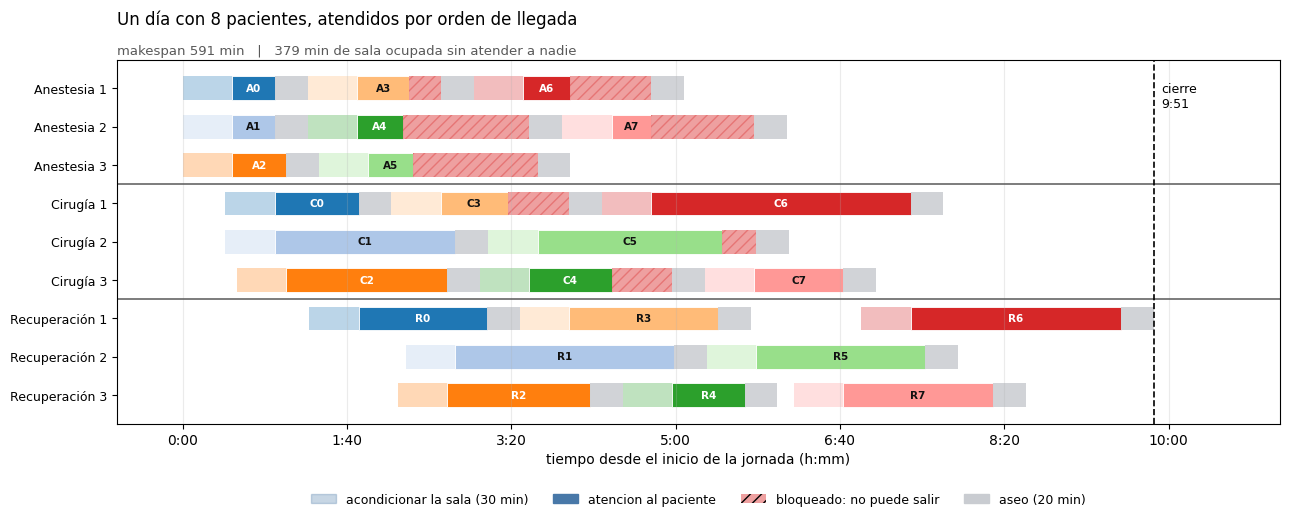

In [ ]:
dia = DIAS["I01"]
dibujar_gantt(regla("FIFO", dia), dia, "Un día con 8 pacientes, atendidos por orden de llegada")
plt.show()

### Cómo se lee este gráfico

Se llama **diagrama de Gantt** y es la forma estándar de mostrar una planificación en
el tiempo. Vale la pena entenderlo bien, porque va a ser tu principal herramienta para
darte cuenta de qué está haciendo tu programa.

**El eje horizontal es el tiempo**, desde que abre el recinto. La etiqueta `3:20`
significa "tres horas y veinte minutos después de abrir".

**Cada fila es una sala.** Hay nueve: tres de anestesia, tres pabellones y tres de
recuperación. Están separadas por líneas horizontales gruesas para que se distingan
las tres etapas.

**Cada color es un paciente**, y lo puedes seguir de arriba abajo: el mismo color
aparece primero en una fila de anestesia, después en una de cirugía y por último en
una de recuperación. Ese es su recorrido por el hospital.

**Cada bloque de atención lleva una etiqueta** con la inicial de la etapa y el número
del paciente:

| Etiqueta | Etapa | Fila donde aparece |
|---|---|---|
| **A**5 | **A**nestesia | Anestesia 1, 2 o 3 |
| **C**5 | **C**irugía | Cirugia 1, 2 o 3 |
| **R**5 | **R**ecuperación | Recuperacion 1, 2 o 3 |

Así, el paciente 5 aparece tres veces en el gráfico: primero como `A5`, después como
`C5` y finalmente como `R5`. Sigue esos tres bloques con la vista y verás su paso por
el hospital, incluidos los ratos en que estuvo esperando.

Los bloques muy angostos no alcanzan a mostrar su etiqueta, pero el color permite
identificarlos igual.

**Los cuatro tipos de bloque:**

| Bloque | Qué es |
|---|---|
| Color pálido, antes del bloque fuerte | Acondicionar la sala, 30 minutos |
| Color fuerte, con la etiqueta | El paciente siendo atendido |
| Rayado rojo | El paciente ya terminó pero **no puede salir** |
| Gris, al final | Aseo de la sala, 20 minutos |

Los bloques pálidos y grises son trabajo sobre la **sala**; el bloque fuerte del medio
es lo único que le ocurre al **paciente**.

**La línea negra cortada** al final marca el makespan: la hora de cierre. Es el número
que hay que empujar hacia la izquierda.

Arriba del gráfico aparecen dos cifras: el makespan y cuántos minutos de sala se
gastaron **ocupados sin atender a nadie**.

### Los bloques rayados en rojo son el problema

Son pacientes que ya terminaron y no pueden salir, porque la etapa siguiente está
llena. La sala donde están queda ocupada sin atender a nadie.

Fíjate dónde aparecen: sobre todo en las filas de arriba, en anestesia. Pero el
problema **no está ahí**. Está en recuperación, que se llena y tapa lo que viene
atrás. Es como un embotellamiento en la carretera: el auto de adelante frena, y la
fila de atrás crece durante kilómetros.

Ahora mira lo mismo con **16 pacientes**, el doble de carga:

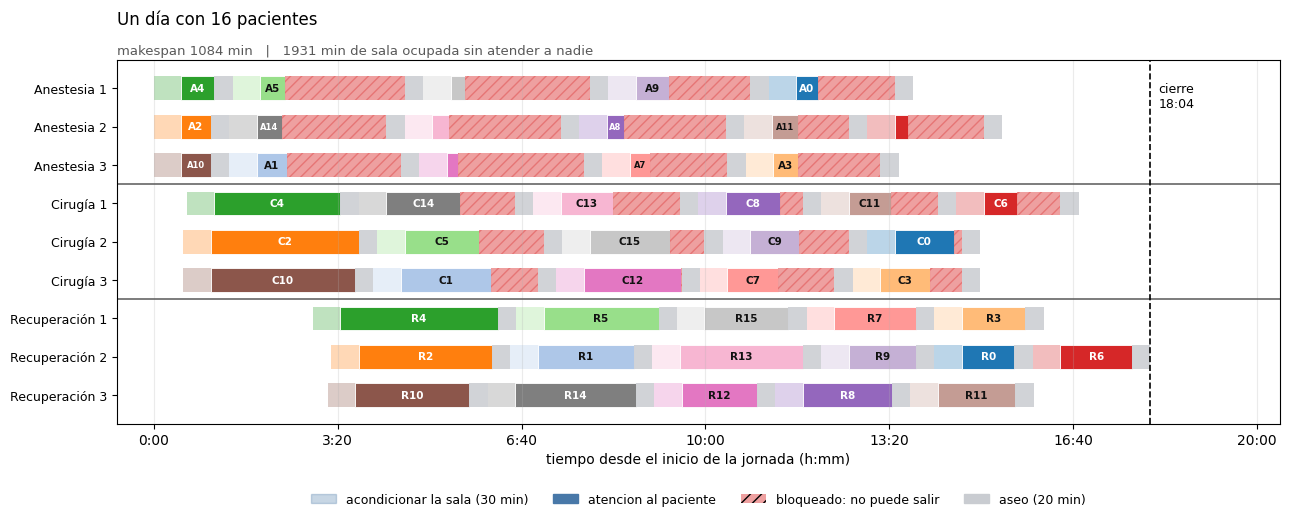

In [ ]:
dia16 = DIAS["I21"]
dibujar_gantt(regla("LPT", dia16), dia16, "Un día con 16 pacientes")
plt.show()

Casi toda la zona de anestesia está rayada. Con esta carga el sistema pasa más
tiempo bloqueado que atendiendo pacientes.

Y esto no se arregla comprando más pabellones: los pabellones ya están ahí, tapados.
Lo que hay que cambiar es **el orden**.

## 2. De qué está hecho un día

Un día quirúrgico es simplemente una lista de pacientes, y de cada paciente se sabe
cuántos minutos se demora en cada una de las tres etapas:

| paciente | anestesia | cirugia | recuperacion |
|---|---|---|---|
| 0 | 25 min | 95 min | 100 min |
| 1 | 31 min | 60 min | 70 min |
| ... | | | |

Son los minutos de **atención al paciente**. Los 30 de acondicionar la sala y los 20
de aseo no van acá: son iguales para todos y los agrega el simulador.

Eso es todo: no hay ningún dato oculto.

Los tiempos no son todos parecidos: hay pacientes cortos, medianos y largos, igual que
en un hospital real. Esa mezcla es la que hace que el orden importe. Si todos los
pacientes fueran idénticos, cualquier orden daría lo mismo.

Hay **30 días distintos**: 10 con 8 pacientes, 10 con 12 y 10 con 16. Son los mismos
para todos los equipos, así que los resultados son comparables.

En código, un día es un arreglo de tres columnas. Los tienes todos en el diccionario
`DIAS`, y uno suelto con `cargar("I21")`. Así se ve por dentro:

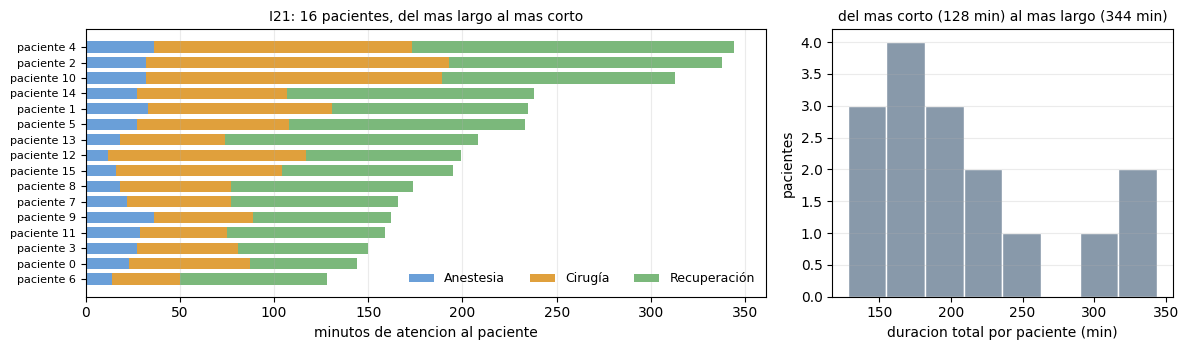

Los datos crudos están en el DataFrame `datos`, por si los quieres mirar:
instancia  n  paciente  anestesia  cirugia  recuperacion
      I01  8         0         26       51            78
      I01  8         1         26      110           133
      I01  8         2         33       98            87


In [ ]:
ficha_dia(DIAS["I21"], "I21")
plt.show()

print("Los datos crudos están en el DataFrame `datos`, por si los quieres mirar:")
print(datos.head(3).to_string(index=False))

### Cómo se lee esta figura

**A la izquierda**, una barra por paciente, ordenadas del más largo al más corto. Cada
barra está partida en tres colores, uno por etapa: azul la anestesia, naranjo la
cirugía, verde la recuperación. El largo total de la barra es lo que ese paciente
ocupa de atención en todo el día.

Mira las proporciones: la anestesia es siempre corta, y la recuperación suele ser tan
larga como la cirugía o más. Esa es la razón de fondo por la que recuperación se
convierte en el cuello de botella.

**A la derecha**, cuántos pacientes hay de cada duración. Sirve para ver si el día
tiene muchos casos parecidos o una mezcla desbalanceada. Un día con dos cirugías muy
largas y catorce cortas se comporta muy distinto de uno con dieciséis medianas.

## 3. Prueba distintos órdenes

Ahora experimenta. Cambia el día y el orden, y mira cómo se mueve el calendario.

Lo más instructivo es tomar **un mismo día y probarle órdenes distintos**: vas a ver
que la hora de cierre cambia en horas, con exactamente los mismos pacientes, las
mismas salas y los mismos tiempos de atención. Lo único distinto es quién entra
antes.

In [ ]:
def explorar(dia="I21", orden="LPT", semilla=0):
    d = DIAS[dia]
    if orden == "aleatorio":
        secuencia = list(np.random.default_rng(semilla).permutation(len(d)))
    else:
        secuencia = regla(orden, d)
    mk = simular_dia(secuencia, d)["makespan"]
    dibujar_gantt(secuencia, d, f"{dia} — orden {orden} — cierra a las {mk/60:.1f} horas")
    plt.show()

try:
    from ipywidgets import interact, Dropdown, IntSlider
    interact(explorar,
             dia=Dropdown(options=INSTANCIAS, value="I21", description="día:"),
             orden=Dropdown(options=["FIFO", "SPT", "LPT", "aleatorio"],
                            value="LPT", description="orden:"),
             semilla=IntSlider(value=0, min=0, max=20, description="barajar:"))
except Exception:
    explorar("I21", "LPT")     # sin widgets, versión estática

interactive(children=(Dropdown(description='día:', index=20, options=('I01', 'I02', 'I03', 'I04', 'I05', 'I06'…

Las tres reglas que aparecen en el menú son las clásicas de la literatura:

| regla | qué hace | idea detrás |
|---|---|---|
| **FIFO** | por orden de llegada | la más justa, y la que usan casi todos los hospitales |
| **SPT** | los pacientes más cortos primero | despachar rápido a muchos, para que la fila avance |
| **LPT** | los pacientes más largos primero | sacarse de encima temprano lo pesado |

Las tres son **deterministas**: dadas las mismas duraciones, siempre entregan el mismo
orden y el mismo makespan. Por eso sirven como punto de comparación honesto — tu
resultado y el de otro equipo se miden contra exactamente lo mismo.

### Qué hace "barajar"

La cuarta opción del menú, **aleatorio**, no sigue ninguna regla: **baraja** a los
pacientes, igual que se barajan naipes. Toma la lista de pacientes y la desordena
por completo, sin mirar cuánto dura cada uno.

El deslizador **barajar** elige *qué* desorden se usa. Cada número produce un orden
distinto, siempre el mismo para el mismo número — por eso se llama **semilla**: con
la misma semilla, el computador reproduce exactamente el mismo azar. Eso permite que
si encuentras un resultado interesante con la semilla 7, un compañero pueda repetirlo
poniendo 7 y ver lo mismo.

**Para qué sirve.** Un orden al azar es el punto de comparación más honesto que
existe: si una regla no le gana consistentemente al azar, esa regla no está aportando
nada. Muévelo entre 0 y 20 y observa el gráfico:

- la **hora de cierre** cambia bastante de una semilla a otra, a veces en más de una
  hora, con los mismos pacientes y las mismas salas;
- la **cantidad de rayado rojo** también cambia; algunos órdenes producen mucho más
  bloqueo que otros;
- de vez en cuando el azar le gana a una regla clásica, y de vez en cuando pierde feo.

Esa variabilidad es el margen que tu programa va a tratar de explotar. Y es también el
motivo por el que más adelante vas a necesitar estadística: cuando un método tiene azar
adentro, un solo resultado no prueba nada.

## 4. Cómo saber si tu resultado es bueno

Acá aparece algo que en un ramo normal no pasa: **no existe una tabla de respuestas
correctas**. Para los días de 12 y 16 pacientes, nadie en el mundo sabe cuál es el
mejor orden posible — ni nosotros. Encontrarlo con certeza tomaría meses de cómputo.

Pero eso no significa trabajar a ciegas. Cada día tiene **un piso y un techo** que
puedes calcular tú mismo, y tu solución vive entre los dos.

**El piso: el mínimo teórico.** No es una estimación, es una cuenta con resultado
garantizado. Se apoya en dos razonamientos que no se pueden esquivar:

1. Ningún paciente puede terminar antes de haber pasado por sus tres etapas. Así que
   el día no puede durar menos que el recorrido del paciente más largo.
2. Las tres salas de una etapa no pueden procesar todo el trabajo de esa etapa más
   rápido que repartiéndoselo perfectamente, sin un segundo ocioso.

El mayor de esos dos números es el mínimo teórico, y lo calcula `cota_inferior(dia)`.
**Ninguna solución válida puede quedar por debajo.** Si tu programa entrega algo menor,
no descubriste un récord: tienes un error.

**El techo: la mejor de las tres reglas clásicas**, que calcula `mejor_regla(dia)`. Si
tu método no le gana ni a eso, algo no está funcionando.

Entre esos dos vive tu solución, y saber dónde cae te dice si vas bien encaminado:

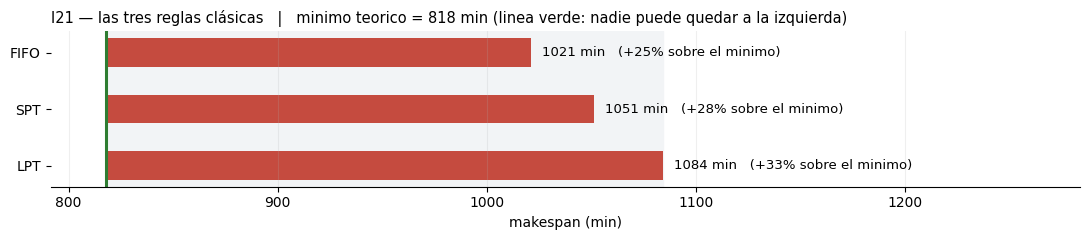

In [ ]:
dia = DIAS["I21"]
resultados_reglas = {nm: simular_dia(regla(nm, dia), dia)["makespan"] for nm in REGLAS}
termometro(resultados_reglas, dia, "I21 — las tres reglas clásicas")
plt.show()

### Cómo se lee este gráfico

El eje horizontal es el makespan en minutos, así que **más a la izquierda es mejor**.

La **línea verde vertical** es el mínimo teórico. Es una pared: nadie puede quedar a su
izquierda. La banda gris de fondo marca la zona donde caen los resultados razonables.

Cada barra es un resultado, y arranca en el mínimo. Su largo es **cuánto peor** es ese
resultado que el mínimo, y al lado se indica el porcentaje. El color va de verde a rojo
según qué tan lejos esté.

En este ejemplo se ve que las tres reglas quedan bastante lejos del piso: hay margen
para mejorar, y ese margen es exactamente el espacio en que trabaja tu programa.

**La tabla de diagnóstico:**

| Lo que ves | Qué significa |
|---|---|
| Tu makespan a la izquierda de la línea verde | Imposible. Hay un error en tu código |
| Peor que la mejor regla | Tu búsqueda todavía no funciona |
| Entre la mejor regla y la línea verde | Vas bien, y sabes cuánto margen queda |
| Justo sobre la línea verde | Óptimo, y lo puedes demostrar |

## 5. El límite de intentos

Una idea tentadora: probar todos los órdenes posibles y quedarse con el mejor.

Con 8 pacientes se puede. Son 40.320 órdenes distintos y se prueban en segundos.

Con 16 pacientes son **20.922.789.888.000**. Probándolos a un millón por segundo,
tardarías más de siete meses. Y 16 pacientes es un día quirúrgico modesto.

Por eso el proyecto pone un límite: **20.000 intentos por día**. Un intento es una
llamada al simulador, es decir, probar un orden y ver qué makespan da.

El límite se cuenta en intentos y no en segundos a propósito: así el resultado no
depende de si a tu grupo le tocó un computador más rápido ni de cuánta carga tenga
Colab ese día. Dos ejecuciones del mismo código son comparables siempre.

La clase `Evaluador` lleva la cuenta sola y avisa cuando se acaban. **Toda tu búsqueda
tiene que pasar por ella.**

In [ ]:
dia = DIAS["I21"]
ev = Evaluador(dia, intentos=20_000)

ev(regla("FIFO", dia))          # cada llamada es un intento
ev(regla("LPT", dia))

print(f"Llevas {ev.usados} intentos de {ev.intentos}")
print(f"El mejor makespan que has visto: {ev.mejor:.0f} min")
print(f"Con este orden: {ev.mejor_orden}")

Llevas 2 intentos de 20000
El mejor makespan que has visto: 1021 min
Con este orden: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


### Cómo se mide "mejorar"

De aquí en adelante, en vez de comparar minutos crudos vas a ver un **cociente**:

    tu makespan  /  makespan de la mejor regla clásica

- si empatas con la regla, ese día vale 1,00
- si cierras un 10% antes, vale 0,90
- si lo haces peor que la regla, pasa de 1,00

Y para resumir los 30 días se promedian esos cocientes. **Menor es mejor.**

¿Por qué dividir, en vez de promediar los minutos directamente? Porque un día de 16
pacientes cierra alrededor de los 1.000 minutos y uno de 8 anda por los 550. Si se
promediaran los minutos crudos, los días grandes dominarían el resultado y daría casi
lo mismo lo que hicieras en los chicos. Al dividir, los 30 días pesan igual.

---

# 6. Acá empieza tu trabajo

Esta sección tiene dos celdas de código:

- **6A** contiene un método de búsqueda que ya funciona, comentado línea por línea. No
  hay que escribirlo, hay que entenderlo: de ahí sale el vocabulario que usa el resto
  del proyecto.
- **6B** es donde va tu método. Viene vacío, con los pasos indicados como comentarios.

De aquí en adelante vas a encontrar bloques marcados así:

> **TAREA n.** Descripción de lo que hay que hacer.

Cada uno tiene debajo una celda de código lista para trabajar, con el andamio escrito
como comentarios. Son el trabajo concreto del proyecto: si te saltas las tareas, no
tienes informe.

Empieza leyendo 6A completo.

## 6A. Un método que ya funciona

Casi todos los métodos de búsqueda comparten la misma estructura, y una vez que la
reconoces, todos se parecen. Son **cuatro piezas**:

| Pieza | Qué decide |
|---|---|
| **1. Punto de partida** | Desde qué solución arranca la búsqueda |
| **2. Vecindad** | Cómo se genera una solución parecida a la actual |
| **3. Criterio de aceptación** | Cuándo te mueves a la solución nueva |
| **4. Condición de término** | Cuándo parar |

El método de abajo se llama **búsqueda por escalada** (*hill climbing* en inglés).
El nombre viene de la imagen: es como subir un cerro con niebla, sin ver la cima,
dando siempre un paso en la dirección que sube.

Léelo con las cuatro piezas en mente: están marcadas en los comentarios.

Mejor makespan encontrado: 902 min
Intentos usados: 20000


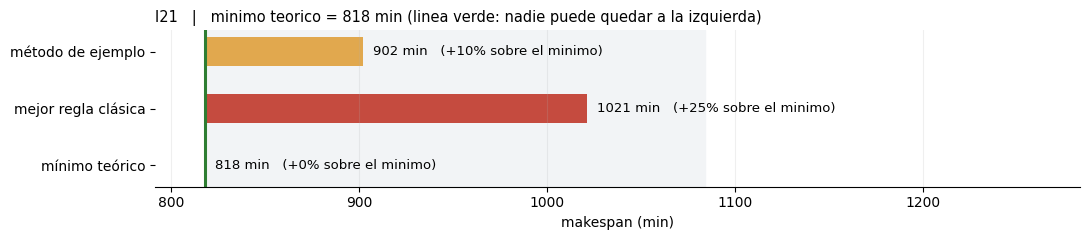

In [ ]:
# ══ CÓMO SE CONECTA ════════════════════════════════════════════════
#   RECIBE   : dia      -> los tiempos de un día (por ejemplo DIAS["I21"])
#              intentos -> cuántas veces puede llamar al simulador
#              seed     -> semilla del azar, para poder repetir una corrida
#   DEVUELVE : un Evaluador, del que después se leen  .mejor  y  .mejor_orden
#   LA USAN  : las secciones 7, 8 y 9, que le pasan un día y leen el resultado
# ═══════════════════════════════════════════════════════════════════

def metodo_ejemplo(dia, intentos=20_000, seed=0):
    """Búsqueda por escalada: cambios pequeños, y me quedo solo si mejoro."""

    rng = np.random.default_rng(seed)   # generador de azar, controlado por la semilla
    n = len(dia)                        # cuántos pacientes tiene este día

    # ── PIEZA 4: la condición de término ───────────────────────────
    # El Evaluador es quien cuenta los intentos. Cada vez que lo llamas con un
    # orden, te devuelve el makespan y descuenta un intento. Cuando se acaban,
    # lanza SinIntentos, que atrapamos más abajo para terminar ordenadamente.
    ev = Evaluador(dia, intentos)

    # ── PIEZA 1: el punto de partida ───────────────────────────────
    # Arrancamos desde el orden que propone la regla LPT, que ya es bastante
    # bueno. La alternativa sería partir de un orden al azar.
    #   ¿Qué pasaría si cambias esto? Empezarías más lejos de una buena
    #   solución, pero explorarías una zona distinta del problema.
    actual = regla("LPT", dia)
    valor_actual = ev(actual)          # primer intento gastado

    try:
        while True:                    # el ciclo se corta solo, al quedarse sin intentos

            # ── PIEZA 2: la vecindad ───────────────────────────────
            # Una "vecina" es una solución parecida a la actual. Acá se genera
            # intercambiando de posición a dos pacientes elegidos al azar.
            #   ¿Qué pasaría si cambias esto? Cambiarías la forma del terreno
            #   por el que te mueves, y con eso a qué soluciones puedes llegar.
            vecina = list(actual)                        # copia, para no romper la actual
            a, b = rng.choice(n, 2, replace=False)       # dos posiciones distintas
            vecina[a], vecina[b] = vecina[b], vecina[a]  # las intercambia

            valor_vecina = ev(vecina)  # otro intento gastado

            # ── PIEZA 3: el criterio de aceptación ─────────────────
            # Solo nos movemos si la vecina es mejor. Nunca aceptamos empeorar.
            #   ¿Qué pasaría si cambias esto? Es la pieza más importante de
            #   todas, y la razón por la que este método se estanca.
            if valor_vecina < valor_actual:
                actual = vecina
                valor_actual = valor_vecina

    except SinIntentos:
        pass                           # se acabaron los intentos: salimos del ciclo

    # El Evaluador fue guardando la mejor solución vista, así que basta devolverlo
    return ev


# Probémoslo en un día de 16 pacientes
dia = DIAS["I21"]
ev = metodo_ejemplo(dia)

print(f"Mejor makespan encontrado: {ev.mejor:.0f} min")
print(f"Intentos usados: {ev.usados}")
termometro({"método de ejemplo": ev.mejor,
            "mejor regla clásica": mejor_regla(dia),
            "mínimo teórico": cota_inferior(dia)}, dia, "I21")
plt.show()

### Lo que este método logra, y lo que no

Le gana a la mejor regla clásica, así que buscar sirve. Pero tiene un problema serio
que vas a medir tú mismo en la sección 7:

> **se queda pegado**.

Llega a un punto donde ningún intercambio de dos pacientes mejora nada, y ahí se
detiene, aunque le queden miles de intentos. Está en la cima de un cerro pequeño,
rodeado de bajadas, sin poder ver que hay un cerro más alto al otro lado del valle.
En la jerga eso se llama **óptimo local**.

Buena parte de los métodos de búsqueda que existen se diferencian justamente en cómo
escapan de un óptimo local.

> **TAREA 1.** Antes de escribir nada propio, experimenta con el método
> de ejemplo. Cambia una de sus cuatro piezas, ejecútalo, y anota qué pasó con el
> makespan. Hazlo al menos con dos cambios distintos.
>
> Esto no es relleno: lo que aprendas acá es lo que vas a usar para diseñar tu propio
> método, y las observaciones sirven para justificar tus decisiones en el informe.

In [ ]:
# TAREA 1: copia aqui metodo_ejemplo, cambiale UNA pieza y compara.
#
# Ideas de cambios, de mas facil a mas dificil:
#   - punto de partida: regla("SPT", dia) en vez de regla("LPT", dia),
#     o list(rng.permutation(n)) para arrancar al azar
#   - vecindad: en vez de intercambiar dos pacientes, saca uno y reinsertalo
#     en otra posicion (usa .pop() y .insert())
#   - aceptacion: acepta tambien cuando la vecina empata (<= en vez de <)
#
def metodo_modificado(dia, intentos=20_000, seed=0):
    #Búsqueda por escalada: cambios pequeños, y me quedo solo si mejoro.

    rng = np.random.default_rng(seed)   # generador de azar, controlado por la semilla
    n = len(dia)                        # cuántos pacientes tiene este día

    # ── PIEZA 4: la condición de término ───────────────────────────
    # El Evaluador es quien cuenta los intentos. Cada vez que lo llamas con un
    # orden, te devuelve el makespan y descuenta un intento. Cuando se acaban,
    # lanza SinIntentos, que atrapamos más abajo para terminar ordenadamente.
    ev = Evaluador(dia, intentos)

    # ── PIEZA 1: el punto de partida ───────────────────────────────
    # Arrancamos desde el orden que propone la regla LPT, que ya es bastante
    # bueno. La alternativa sería partir de un orden al azar.
    #   ¿Qué pasaría si cambias esto? Empezarías más lejos de una buena
    #   solución, pero explorarías una zona distinta del problema.
    actual = regla("SPT", dia)
    valor_actual = ev(actual)          # primer intento gastado

    try:
        while True:                    # el ciclo se corta solo, al quedarse sin intentos

            # ── PIEZA 2: la vecindad ───────────────────────────────
            # Una "vecina" es una solución parecida a la actual. Acá se genera
            # intercambiando de posición a dos pacientes elegidos al azar.
            #   ¿Qué pasaría si cambias esto? Cambiarías la forma del terreno
            #   por el que te mueves, y con eso a qué soluciones puedes llegar.
            vecina = list(actual)                        # copia, para no romper la actual
            a, b = rng.choice(n, 2, replace=False)       # dos posiciones distintas
            vecina[a], vecina[b] = vecina[b], vecina[a]  # las intercambia
            #vecina_pop = vecina.pop(a)
            #vecina.insert(b, vecina_pop)
            valor_vecina = ev(vecina)  # otro intento gastado

            # ── PIEZA 3: el criterio de aceptación ─────────────────
            # Solo nos movemos si la vecina es mejor. Nunca aceptamos empeorar.
            #   ¿Qué pasaría si cambias esto? Es la pieza más importante de
            #   todas, y la razón por la que este método se estanca.
            if valor_vecina < valor_actual:
                actual = vecina
                valor_actual = valor_vecina

    except SinIntentos:
        pass                           # se acabaron los intentos: salimos del ciclo

    # El Evaluador fue guardando la mejor solución vista, así que basta devolverlo
    return ev

dia = DIAS["I21"]
print("original :", metodo_ejemplo(dia).mejor)
print("modificado:", metodo_modificado(dia).mejor)

original : 902.0
modificado: 907.0


## 6B. Tu método

```
══ QUÉ TIENES QUE HACER EN ESTA SECCIÓN ═══════════════════════════

 [ ] 1. Lee `metodo_ejemplo` completo. Cámbiale algo pequeño,
        córrelo, y mira qué pasó.

 [ ] 2. Corre `mi_metodo` tal como viene. No busca nada: devuelve
        el orden de llegada y ya. Ese es tu punto cero.

 [ ] 3. Haz que `mi_metodo` busque de verdad. Empieza copiando la
        idea de `metodo_ejemplo` y cambiando UNA sola cosa: cómo
        genera la solución vecina.

 [ ] 4. Ataca el estancamiento. `metodo_ejemplo` deja de mejorar muy
        temprano — lo vas a comprobar con datos en la sección 7.
        Necesitas alguna forma de escapar de ahí.

 [ ] 5. Cuando le ganes a `metodo_ejemplo` en la mayoría de los 30
        días, pasa a los experimentos.
═══════════════════════════════════════════════════════════════════
```

La celda de abajo tiene los pasos escritos como comentarios. **Descoméntalos y
complétalos.** Mientras no lo hagas, la función devuelve el orden de llegada sin
buscar nada, para que el resto del notebook siga corriendo.

Conviene no escribir el método completo de una sola vez. Haz funcionar algo simple,
córrelo, mira el número, y recién ahí agrégale complejidad.

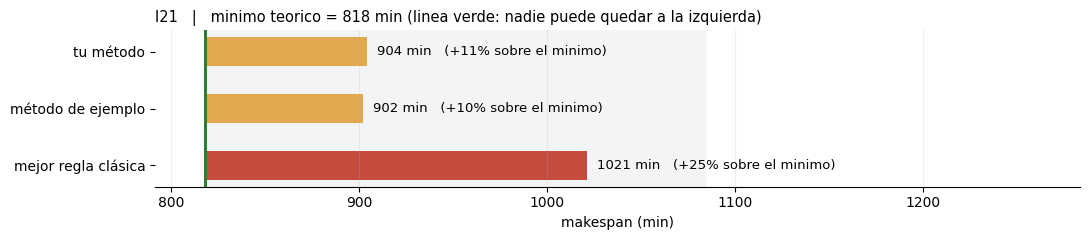

In [ ]:
# ══ CÓMO SE CONECTA ════════════════════════════════════════════════
#   Exactamente igual que metodo_ejemplo: mismas entradas, misma salida.
#   Esto no es opcional — las secciones 7 a 10 esperan un Evaluador.
#
#   RECIBE   : dia, intentos, seed
#   DEVUELVE : un Evaluador
# ═══════════════════════════════════════════════════════════════════

def mi_metodo(dia, intentos=20_000, seed=0):
    """Tu técnica de búsqueda."""

    rng = np.random.default_rng(seed)
    n = len(dia)
    ev = Evaluador(dia, intentos)

    # ── PASO 1: ELIGE UN PUNTO DE PARTIDA ──────────────────────────
    # Necesitas un primer orden y su makespan. Dos opciones:
    #   - el de una regla:      regla("LPT", dia)  o  regla("SPT", dia)
    #   - uno al azar:          list(rng.permutation(n))
    # ¿Cuál conviene? Es una pregunta empírica: pruébalas y compara.
    #
    actual = regla("SPT", dia)
    valor_actual = ev(actual)

    # ── PASO 2: DEFINE TU VECINDAD ─────────────────────────────────
    # Una función que reciba un orden y devuelva otro parecido. El ejemplo
    # intercambia dos pacientes. Otra opción clásica es la INSERCIÓN: sacar
    # un paciente de la fila y volver a meterlo en otra posición. En Python
    # eso se hace con .pop() y .insert().
    # Las dos vecindades producen resultados distintos. Averigua por qué.
    #
    # def vecina_de(orden):
    #     ...
    def vecina_de(orden, a, b):
      vecina = list(orden)                        # copia, para no romper la actual
      #a, b = rng.choice(n, 2, replace=False)       # dos posiciones distintas
      #vecina[a], vecina[b] = vecina[b], vecina[a]
      vecina_pop = vecina.pop(a)
      vecina.insert(b, vecina_pop)
      valor_vecina = ev(vecina)  # otro intento gastado


      return vecina, valor_vecina

    # ── PASO 3: DECIDE CUÁNDO TE MUEVES ────────────────────────────
    # Esta es la pieza que más importa. Si solo aceptas mejoras, te vas a
    # estancar igual que el método de ejemplo. Necesitas alguna forma de
    # escapar de un óptimo local. Tres caminos, de menor a mayor dificultad:
    #   - reiniciar desde otro punto cuando llevas muchos intentos sin mejorar
    #   - aceptar de vez en cuando una solución peor  ("recocido simulado")
    #   - prohibir volver sobre los últimos movimientos  ("búsqueda tabú")
    # Busca cómo funcionan y elige uno.

    # ── PASO 4: ARMA EL CICLO ──────────────────────────────────────
    # Todo lo anterior va dentro de un  while True:  envuelto en
    #   try: ...  except SinIntentos: pass
    # tal como en metodo_ejemplo. El Evaluador corta la ejecución solo.
    #


    """temperatura = 100.0
    try:
        while True:
          a, b = rng.choice(n, 2, replace=False)
          vecina, valor_vecina, = vecina_de(actual, a, b)
          delta = valor_vecina - valor_actual

          if delta < 0:
              actual = vecina
              valor_actual = valor_vecina
          else:
              probabilidad = np.exp(-delta / temperatura)
              if rng.random() < probabilidad:
                  actual = vecina
                  valor_actual = valor_vecina
          temperatura *= 0.995
    except SinIntentos:
        pass"""

    tabu = []
    tenure = 10 #max(5, n // 3)

    try:
        while True:

          mejores_vecina = None
          mejor_valor_vecina = float("inf")
          mejor_movimiento = None

          for i in range(10):
            a, b, = rng.choice(n, 2, replace=False)
            movimiento = (a, b)
            vecina, valor_vecina = vecina_de(actual, a, b)

            es_tabu = movimiento in tabu

            aspiracion = valor_vecina < ev.mejor
            if es_tabu and not aspiracion:
              continue

            if valor_vecina < mejor_valor_vecina:
              mejores_vecina = vecina
              mejor_valor_vecina = valor_vecina
              mejor_movimiento = movimiento

          if mejores_vecina is None:
            continue

          actual = mejores_vecina
          valor_actual = mejor_valor_vecina

          tabu.append(mejor_movimiento)
          if len(tabu) > tenure:
            tabu.pop(0)

    except SinIntentos:
      pass

    # ── PROVISORIO: BÓRRALO CUANDO TU BÚSQUEDA FUNCIONE ────────────
    # Por ahora no busca nada: devuelve el orden de llegada y se acabó.
    #ev(regla("FIFO", dia))

    return ev

#print(type(ev.mejor), ev.mejor)
# Comprobación rápida: ¿le gana al método de ejemplo?
dia = DIAS["I21"]
termometro({"tu método": mi_metodo(dia).mejor,
            "método de ejemplo": metodo_ejemplo(dia).mejor,
            "mejor regla clásica": mejor_regla(dia)}, dia, "I21")
plt.show()

Sin tocar nada, tu método queda tercero de tres, porque todavía no busca. Cuando
completes el paso 3 de la lista, esa barra debería pasar al primer lugar.

### Los gráficos no se actualizan solos

Todo lo que viene de aquí en adelante —los termómetros, las curvas, la tabla
comparativa, el archivo de entrega— se calcula **llamando a `mi_metodo`**. Mientras
esa función devuelva el orden de llegada, todos esos resultados van a mostrar un
método que no busca.

Cada vez que edites 6B, el ciclo es el mismo:

1. editas `mi_metodo` en la celda 6B
2. **ejecutas la celda 6B** (si no, Python sigue usando la versión anterior)
3. vuelves a ejecutar las celdas de más abajo que te interesen

En Colab, `Entorno de ejecución > Ejecutar celdas posteriores` corre de una vez todo
lo que viene desde la celda actual hacia abajo. Es lo más cómodo mientras iteras.

## 7. Experimento 1 — ¿Cuántos intentos valen la pena?

Tu método tiene 20.000 intentos. ¿Los aprovecha todos?

> **¿A partir de qué punto gastar más intentos deja de comprar mejoras?**

Tiene una consecuencia práctica: si un hospital tuviera que replanificar el día
después de una urgencia, necesitaría saber cuánto tiempo de cómputo conviene esperar.

Tu método tiene azar adentro, así que dos corridas del mismo código dan resultados
distintos. Con un solo día y una sola semilla no se puede concluir nada. Por eso el
barrido de abajo usa **3 días y 3 semillas** por configuración, y reporta el promedio
junto con la dispersión.

barriendo:   0%|          | 0/3 [00:00<?, ?it/s]

                              mean     std
metodo            intentos                
método de ejemplo 1000      0.9526  0.0380
                  5000      0.9526  0.0380
                  20000     0.9526  0.0380
tu método         1000      0.9468  0.0227
                  5000      0.9377  0.0282
                  20000     0.9327  0.0309


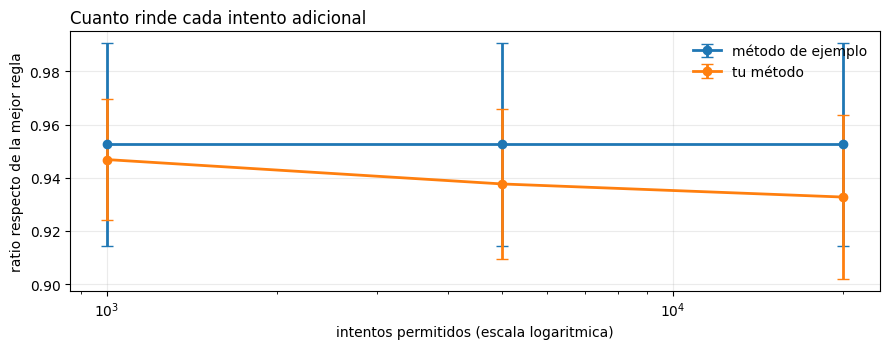

In [ ]:
barrido = barrer_intentos(
    metodos={"método de ejemplo": metodo_ejemplo, "tu método": mi_metodo},
    dias={k: DIAS[k] for k in ["I05", "I15", "I25"]},
    lista_intentos=[1_000, 5_000, 20_000],
    semillas=3)

print(barrido.groupby(["metodo", "intentos"])["ratio"]
             .agg(["mean", "std"]).round(4).to_string())

grafico_intentos(barrido)
plt.show()

Mira la curva del método de ejemplo: **es plana**. Con 1.000 intentos llega
prácticamente al mismo resultado que con 20.000. Ese es el estancamiento del que
hablábamos, medido: el 95% de los intentos se desperdicia.

Un método que sí sepa escapar de los óptimos locales debería mostrar una curva que
sigue bajando.

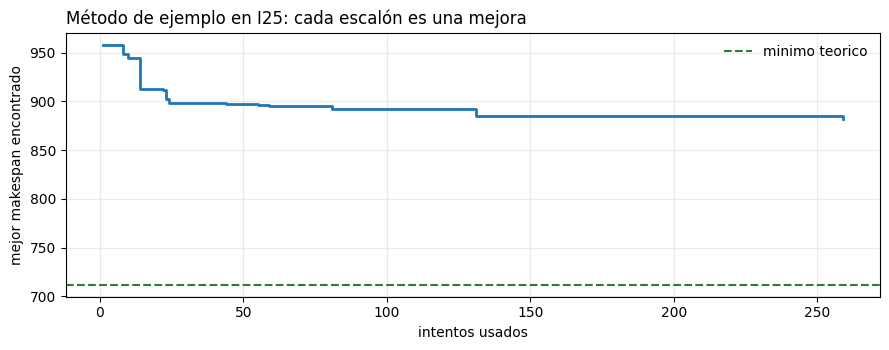

In [ ]:
ev = metodo_ejemplo(DIAS["I25"], 20_000)
grafico_convergencia(ev, DIAS["I25"], "Método de ejemplo en I25: cada escalón es una mejora")
plt.show()

En este gráfico cada escalón hacia abajo es un momento en que la búsqueda encontró
algo mejor. Mira dónde ocurre el último escalón y compáralo con los 20.000 intentos
disponibles: todo lo que viene después no produce ninguna mejora.

> **TAREA 2.** Dibuja la misma curva para tu método y ponla al lado de
> la de arriba. ¿Sigue bajando cuando la del ejemplo ya se aplanó? ¿En qué intento se
> detiene cada una?
>
> La comparación entre las dos formas es uno de los resultados centrales del informe.

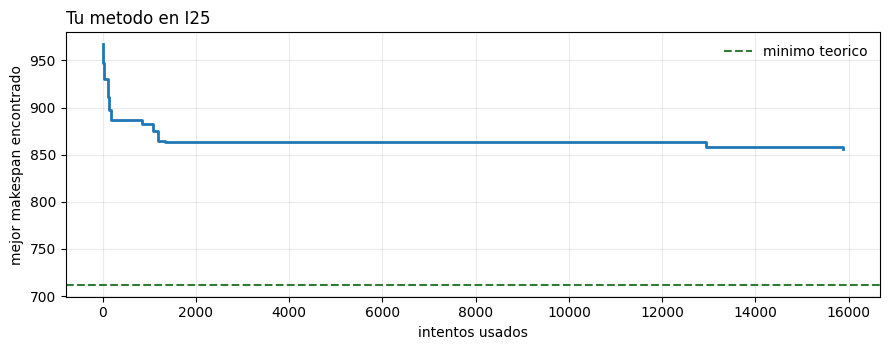

ultimo intento que produjo una mejora: 15876


In [ ]:
# TAREA 2: curva de convergencia de TU metodo, para comparar con la de arriba.
#
ev_mio = mi_metodo(DIAS["I25"], 20_000)
grafico_convergencia(ev_mio, DIAS["I25"], "Tu metodo en I25")
plt.show()
#
# Para responder la pregunta con un numero y no a ojo, el ultimo escalon esta en:
print("ultimo intento que produjo una mejora:", ev_mio.historial[-1][0])

## 8. Experimento 2 — ¿Las diferencias son reales?

Vas a comparar **tres cosas**: la mejor regla clásica, el método de ejemplo, y el tuyo.

### Por qué el promedio no basta

Supón que un método gana por 48 minutos en promedio. Ese número puede venir de dos
situaciones muy distintas:

- ganó un poco en los 30 días, de forma consistente;
- perdió en 20 días y ganó por muchísimo en 10.

El promedio es el mismo, pero la conclusión es opuesta. Si un hospital pregunta "¿me
conviene este método?", en el primer caso la respuesta es sí y en el segundo es
"depende del día".

### La clave: mirar día por día

Tus datos tienen una propiedad valiosa. Cada día entrega **números comparables** para
los tres métodos, sobre exactamente los mismos pacientes, las mismas salas y las mismas
duraciones. Están **emparejados**.

Entonces lo que hay que mirar no son las columnas por separado, sino **la diferencia de
cada día**. Si dos métodos fueran igual de buenos, esas diferencias se repartirían al
azar entre positivas y negativas, y su mediana rondaría cero.

El **test de Wilcoxon pareado** responde justamente eso: dada esa lista de diferencias,
¿es creíble que vengan de dos métodos equivalentes? Entrega un **p-valor**:

> el p-valor es la probabilidad de observar una diferencia al menos tan grande como la
> tuya **si en realidad los dos métodos fueran igual de buenos**.

Un p-valor chico significa que esa explicación es poco creíble. Por convención se usa
0,05 como umbral. Un p de 0,40 significa que lo que viste es perfectamente compatible
con el azar.

`comparar_todos` hace esto por ti para cada par de métodos. Por dentro son tres líneas:

```python
diferencia = np.array(makespans_A) - np.array(makespans_B)
p = wilcoxon(makespans_A, makespans_B).pvalue
victorias = (diferencia < 0).sum()
```

Y al final ajusta los p-valores con **la corrección de Holm**. Hace falta porque al
hacer tres comparaciones a la vez sube la probabilidad de que alguna salga
significativa por pura casualidad — el mismo efecto que tirar tres veces un dado en vez
de una.

### Tres cosas que hay que respetar

1. **Necesitas unos 20 días como mínimo.** Con 5, el p-valor de Wilcoxon **no puede
   bajar de 0,0625** aunque ganes las cinco veces. No es un problema de tus datos: el
   test no tiene suficientes combinaciones posibles para descartar el azar. Por eso el
   proyecto usa 30.
2. **Reporta siempre cuánto ganas, no solo el p-valor.** "Gana en 25 de 30 días, con
   una mediana de 18 minutos" es una frase útil. "p < 0,001" sola no dice nada sobre el
   tamaño del beneficio.
3. **Significativo no es lo mismo que importante.** Con muchos datos, una diferencia de
   dos minutos puede salir estadísticamente significativa y no servirle a ningún
   hospital.

In [ ]:
tabla = tabla_resultados(DIAS,
                        {"metodo_ejemplo": metodo_ejemplo,
                         "mi_metodo": mi_metodo},
                        intentos=20_000)

comparar_todos({"mejor regla":       tabla["mejor_regla"],
                "método de ejemplo": tabla["metodo_ejemplo"],
                "tu método":         tabla["mi_metodo"]})

for col in ("metodo_ejemplo", "mi_metodo"):
    r = (tabla[col] / tabla["mejor_regla"]).mean()
    lado = "antes" if r < 1 else "DESPUÉS"
    print(f"{col:>16}: ratio medio {r:.4f}  ->  cierra un {abs(100*(1-r)):.1f}% "
          f"{lado} que la mejor regla")

resolviendo:   0%|          | 0/30 [00:00<?, ?it/s]

mejor regla  vs  método de ejemplo
    gana mejor regla en 0 dias   |   gana método de ejemplo en 29   |   empatan en 1
    mediana de la diferencia: +43.5 min   (promedio +48.1)
    Wilcoxon pareado: p = 0.00000  ->  p ajustado por Holm = 0.00001  ->  la diferencia es real

mejor regla  vs  tu método
    gana mejor regla en 0 dias   |   gana tu método en 29   |   empatan en 1
    mediana de la diferencia: +54.0 min   (promedio +59.8)
    Wilcoxon pareado: p = 0.00000  ->  p ajustado por Holm = 0.00001  ->  la diferencia es real

método de ejemplo  vs  tu método
    gana método de ejemplo en 1 dias   |   gana tu método en 24   |   empatan en 5
    mediana de la diferencia: +6.5 min   (promedio +11.7)
    Wilcoxon pareado: p = 0.00002  ->  p ajustado por Holm = 0.00002  ->  la diferencia es real

  metodo_ejemplo: ratio medio 0.9398  ->  cierra un 6.0% antes que la mejor regla
       mi_metodo: ratio medio 0.9256  ->  cierra un 7.4% antes que la mejor regla


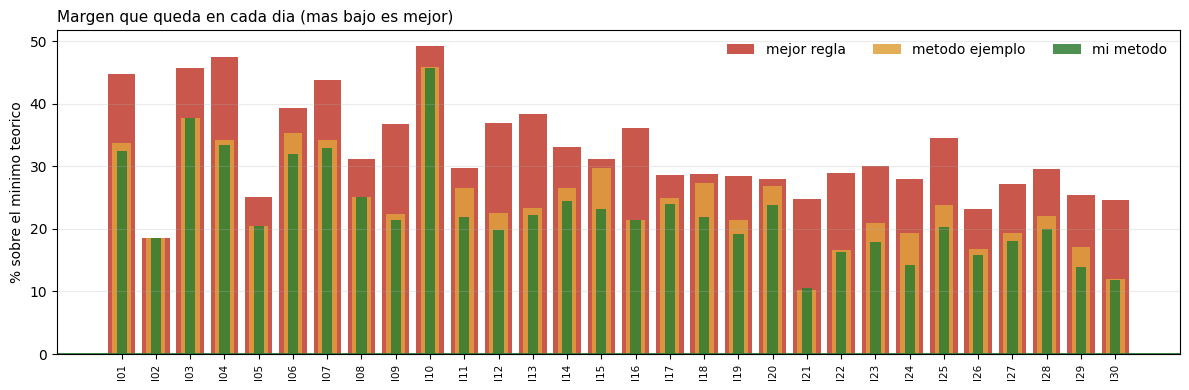

Ratio medio según el tamaño del día:
    metodo_ejemplo  mi_metodo
n                            
8           0.9471     0.9416
12          0.9491     0.9271
16          0.9232     0.9081


In [ ]:
panel_resultados(tabla)
plt.show()

print("Ratio medio según el tamaño del día:")
print((tabla[["metodo_ejemplo", "mi_metodo"]]
       .div(tabla["mejor_regla"], axis=0)
       .groupby(tabla["n"]).mean().round(4).to_string()))

### Cómo se lee el panel

Una columna por día, agrupadas por tamaño. La altura mide **cuánto peor que el mínimo
teórico** es cada resultado, en porcentaje: la línea verde del cero es el mínimo, y
mientras más baja la barra, mejor.

---

> **TAREA 3.** Responde estas cuatro preguntas en el informe, usando los números que
> acabas de generar. Para cada una, indica **de qué parte de la salida** sacaste la
> respuesta.

**1. ¿Cuánto aporta *buscar*, frente a simplemente *ordenar con una regla*?**
Compara la mejor regla con el método de ejemplo. ¿Cuántos días gana? ¿Sobrevive la
diferencia a la corrección de Holm?

**2. ¿Cuánto aporta *buscar bien*, frente a *buscar de forma ingenua*?**
Compara el método de ejemplo con el tuyo. Misma pregunta.

**3. ¿Cuál de los dos saltos es más grande?**
Este es el hallazgo interesante, porque la intuición suele decir una cosa y los datos
otra. Respóndelo con la mediana de las diferencias y el conteo de victorias, no solo
con los promedios.

**4. ¿La ventaja de tu método es igual en los días de 8 pacientes que en los de 16?**
La última tabla te da ese desglose. Si hay diferencia, ¿a qué la atribuyes? Revisa lo
que viste en el Gantt de la sección 1.

## 9. Experimento 3 — Comprobar contra la respuesta exacta

Los días de 8 pacientes tienen solo 40.320 órdenes posibles. Se pueden probar
**todos**, en segundos. Ahí sí existe la respuesta correcta, y se puede calcular con
certeza.

Es el único caso del proyecto en que se puede verificar si tu método encontró lo mejor
que había.

La enumeración no usa el Evaluador, porque no es una búsqueda sino un cálculo
exhaustivo. Por eso no consume tus 20.000 intentos.

In [ ]:
from itertools import permutations
import time

for nombre in ["I01", "I05", "I10"]:
    d = DIAS[nombre]
    t0 = time.time()
    optimo = min(simular_dia(q, d)["makespan"] for q in permutations(range(len(d))))
    seg = time.time() - t0

    mio = mi_metodo(d).mejor
    ejemplo = metodo_ejemplo(d).mejor
    estado = "lo alcanzaste" if mio <= optimo + 1e-6 else f"te falta {mio - optimo:.0f} min"
    print(f"{nombre}: óptimo real = {optimo:.0f}   ejemplo = {ejemplo:.0f}   "
          f"tu método = {mio:.0f}   -> {estado}   ({seg:.1f} s enumerando)")

NameError: name 'DIAS' is not defined

La celda de arriba solo revisa tres días. Los diez días de 8 pacientes son
`I01` a `I10`.

> **TAREA 4.** Amplía la enumeración a los diez días chicos y reporta en
> cuántos alcanzaste el óptimo exacto.
>
> Después, con el tiempo que acabas de medir, estima cuánto tardaría enumerar un día
> de 12 pacientes (479.001.600 órdenes) y uno de 16 (20.922.789.888.000). Compara esas
> cifras con los 20.000 intentos que usa tu método.

In [ ]:
# TAREA 4: enumeracion completa de los diez dias de 8 pacientes.
#
alcanzados = 0
for nombre in [f"I{k:02d}" for k in range(1, 11)]:
    d = DIAS[nombre]
    optimo = min(simular_dia(q, d)["makespan"] for q in permutations(range(len(d))))
    mio = mi_metodo(d).mejor

    if mio <= optimo + 510.0:
      alcanzados += 1
      estado = "lo alcanzaste"
    else:
      estado = f"te falta {mio - optimo:.0f} min"

print(f"Alcanzaste el optimo en {alcanzados} de 10 dias")

# Estimacion del tiempo de enumeracion para dias mas grandes:
# ordenes_8  = 40_320
# ordenes_12 = 479_001_600
# ordenes_16 = 20_922_789_888_000
# segundos_por_orden = seg / ordenes_8      # seg viene de la celda anterior
# ...

Alcanzaste el optimo en 10 de 10 dias


## 10. Generar la entrega

Esta celda corre tu método en los 30 días, revisa que cada solución sea válida y
escribe `soluciones.csv`. Ese archivo se entrega junto con el informe.

### Qué revisa el verificador

Reconstruye el calendario completo a partir de tu orden y comprueba cuatro cosas:

1. **Que el orden use a cada paciente exactamente una vez.** Ni repetidos ni ausentes.
2. **Que ninguna sala atienda a dos pacientes a la vez**, contando el acondicionamiento y el
   aseo como parte de la ocupación.
3. **Que se respete el orden de las etapas**: nadie entra a cirugía antes de terminar
   la anestesia, ni a recuperación antes de terminar la cirugía.
4. **Que se cumpla la regla de bloqueo**, es decir, que no haya esperas negativas —
   nadie sale de una sala antes de que la siguiente lo reciba.

Si algo falla, la celda se detiene y el archivo no se escribe.

En la práctica esto casi nunca falla, porque tú entregas solo un orden y el simulador
construye el calendario respetando las reglas. Un orden mal armado —con pacientes
repetidos o faltantes— es el único error que puedes cometer.

In [ ]:
filas, ratios = [], []
for nombre, d in DIAS.items():
    ev = mi_metodo(d, 20_000, seed=0)
    orden = ev.mejor_orden

    errores = verificar(orden, d, simular_dia(orden, d))
    if errores:
        raise ValueError(f"{nombre}: solución inválida -> {errores[0]}")

    ratios.append(ev.mejor / mejor_regla(d))
    filas.append({"instancia": nombre, "orden": " ".join(map(str, orden)),
                  "makespan": ev.mejor, "intentos": ev.usados})

pd.DataFrame(filas).to_csv("soluciones.csv", index=False)
print("soluciones.csv listo: 30 días, todos válidos")
print(f"Resultado global: {np.mean(ratios):.4f}")

soluciones.csv listo: 30 días, todos válidos
Resultado global: 0.9256


---

## Qué va en el informe

1. **Cómo funciona tu método.** Las cuatro piezas de la sección 6A, aplicadas al tuyo:
   punto de partida, vecindad, criterio de aceptación y condición de término. Por qué
   elegiste cada una. Si probaron alternativas, cuéntenlas.
2. **Experimento 1.** ¿Cuántos intentos valen la pena? Comparen la forma de las curvas
   del método de ejemplo y del suyo.
3. **Experimento 2.** Las cuatro conclusiones de la sección 8, respondidas con números.
4. **Experimento 3.** ¿En cuántos de los diez días chicos alcanzaron el óptimo? ¿Cuánto
   tardaría enumerar los días de 12 y 16?
5. **Una conclusión operativa.** Si un hospital les preguntara "¿qué hago mañana?",
   ¿qué le responderían, y qué tan seguros están de esa respuesta?

Incluyan también **lo que no funcionó**: algún método o variante que probaron y
descartaron, con la razón por la que lo descartaron y el dato que los llevó a esa
conclusión.